# Data Validation

Using inflows of steel into the US building stock from arehart et al (2020) and US steel production data from Net Zero Steel, we will attempt to validate the 2 year MA power law model 

# Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## Read in Data

In [19]:
BASE_DIR = Path.cwd().parent
fig_dir = BASE_DIR / 'figures'

df_steel_forecast = pd.read_csv(BASE_DIR / 'output_data/steel_forecast.csv', index_col=0)
df_arehart_forecast = pd.read_excel(BASE_DIR / 'input_data/validation_data.xlsx', index_col=0, sheet_name='arehart validation')
df_net_zero_forecast = pd.read_excel(BASE_DIR / 'input_data/validation_data.xlsx', index_col=0, sheet_name='net zero steel validation')
df_pct_construction = pd.read_excel(BASE_DIR / 'input_data/validation_data.xlsx',  sheet_name='construction steel pct')
df_pct_total =  pd.read_excel(BASE_DIR / 'input_data/validation_data.xlsx',  sheet_name='total steel pct')

## Data Prep
Using percentages of structural steel of overall production and of construction related production, adjust the validation data so it is measuring the same thing: structural steel production

In [20]:
pct_const = df_pct_construction.iloc[0] 

df_arehart_forecast_const = pd.concat(
    {col: df_arehart_forecast[col].apply(lambda v: v * pct_const) for col in df_arehart_forecast.columns},
    axis=1
)

df_arehart_forecast_const.columns = [f"{col}_{sub.replace('pct_', '')}" for col, sub in df_arehart_forecast_const.columns]

df_arehart_forecast_const.head()

,inflows_ssp1_low,inflows_ssp1_avg,inflows_ssp1_high,inflows_ssp2_low,inflows_ssp2_avg,inflows_ssp2_high,inflows_ssp3_low,inflows_ssp3_avg,inflows_ssp3_high,inflows_ssp4_low,inflows_ssp4_avg,inflows_ssp4_high,inflows_ssp5_low,inflows_ssp5_avg,inflows_ssp5_high
Year,,,,,,,,,,,,,,,
2017,5.914065,7.122664,9.503263,5.916557,7.125664,9.507266,5.856469,7.053297,9.410712,8.298957,9.994932,13.335525,8.325132,10.026457,13.377587
2018,5.884465,7.087014,9.455698,5.883940,7.086382,9.454854,5.821455,7.011127,9.354448,8.060350,9.707563,12.952110,8.085295,9.737606,12.992194
2019,5.852408,7.048406,9.404186,5.848300,7.043459,9.397585,5.782936,6.964737,9.292552,7.824386,9.423378,12.572942,7.848036,9.451861,12.610945
2020,5.815868,7.004399,9.345471,5.807526,6.994352,9.332066,5.738745,6.911515,9.221542,7.590024,9.141122,12.196348,7.612297,9.167946,12.232137
2021,5.772594,6.952282,9.275934,5.759282,6.936249,9.254543,5.686493,6.848585,9.137579,7.358607,8.862413,11.824486,7.379409,8.887465,11.857912


In [21]:
pct_total = df_pct_total.iloc[0]  

df_net_zero_forecast_const = pd.concat(
    {col: df_net_zero_forecast[col].apply(lambda v: v * pct_total) for col in df_net_zero_forecast.columns},
    axis=1
)

df_net_zero_forecast_const.columns = [f"{col}_{sub.replace('pct_', '')}" for col, sub in df_net_zero_forecast_const.columns]

df_net_zero_forecast_const = df_net_zero_forecast_const / 1e3

In [22]:
df_steel_forecast = df_steel_forecast / 1e3

## Plot Comparisons

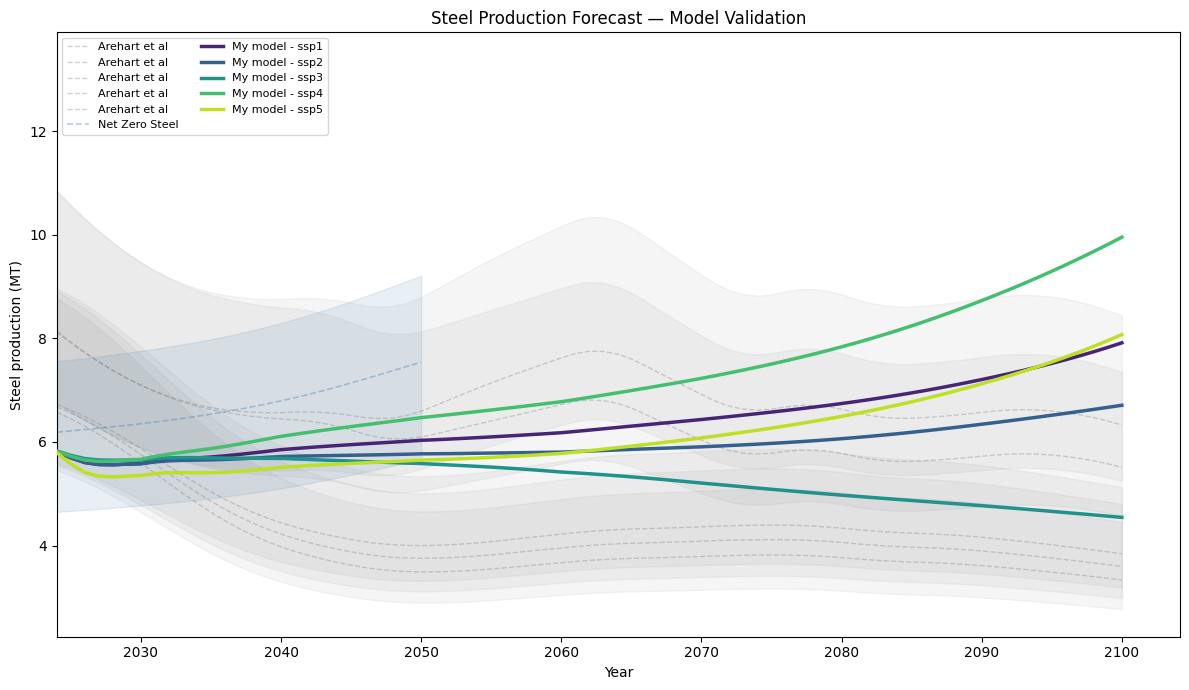

In [ ]:
#######################################################################
# This plot was abandoned in favor of the next one for its readability 
#######################################################################
fig, ax = plt.subplots(figsize=(12, 7))


arehart_ssps = ['ssp1', 'ssp2', 'ssp3', 'ssp4', 'ssp5']
for ssp in arehart_ssps:
    ax.plot(df_arehart_forecast_const.loc[2024:].index,
            df_arehart_forecast_const[f'inflows_{ssp}_avg'].loc[2024:],
            color='gray', alpha=0.35, linewidth=1, linestyle='--', label='Arehart et al')
    ax.fill_between(df_arehart_forecast_const.index,
                     df_arehart_forecast_const[f'inflows_{ssp}_low'],
                     df_arehart_forecast_const[f'inflows_{ssp}_high'],
                     color='gray', alpha=0.08)

ax.plot(df_net_zero_forecast_const.loc[2024:].index,
        df_net_zero_forecast_const['inflows_total_avg'].loc[2024:],
        color='steelblue', alpha=0.4, linewidth=1.2, linestyle='--',
        label='Net Zero Steel')
ax.fill_between(df_net_zero_forecast_const.index,
                 df_net_zero_forecast_const['inflows_total_low'],
                 df_net_zero_forecast_const['inflows_total_high'],
                 color='steelblue', alpha=0.12)

colors = plt.cm.viridis([0.1, 0.3, 0.5, 0.7, 0.9])
for ssp, c in zip(['ssp1', 'ssp2', 'ssp3', 'ssp4', 'ssp5'], colors):
    ax.plot(df_steel_forecast.loc[2024:].index, df_steel_forecast[ssp].loc[2024:],
            color=c, linewidth=2.5, alpha=1.0, label=f'My model - {ssp}', zorder=5)

ax.set_xlabel('Year')
ax.set_ylabel('Steel production (MT)')
ax.set_title('Steel Production Forecast — Model Validation')
ax.legend(loc='upper left', fontsize=8, ncol=2)
ax.set_xlim(left=2024)  # trim early sparse years if desired
plt.tight_layout()
plt.show()

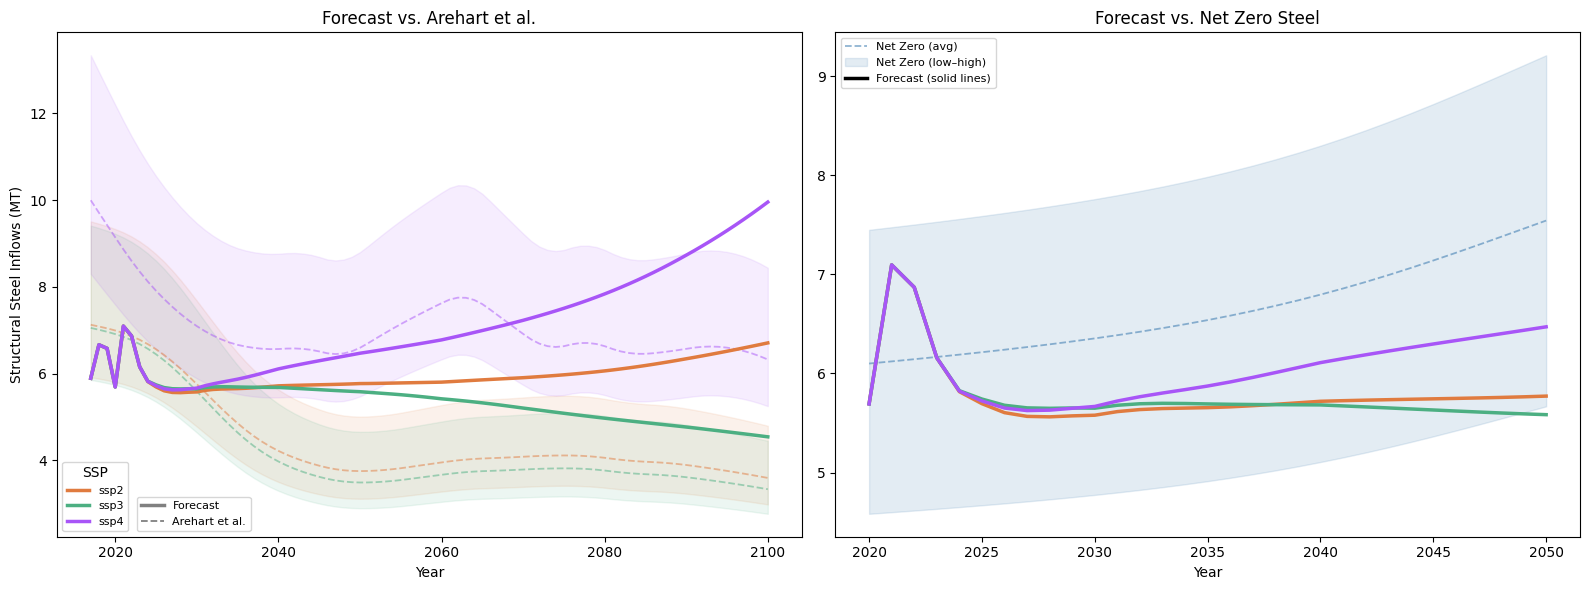

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

ssp_list = ['ssp2', 'ssp3', 'ssp4']
ssp_colors = ['#E07B3F', '#4CAF82', '#A855F7']
ssp_color_map = dict(zip(ssp_list, ssp_colors))

# ─────────────────────────────────────────────────────────────────────────────
# Panel 1: Versus Arehart et al.
# ─────────────────────────────────────────────────────────────────────────────
for ssp in ssp_list:
    c = ssp_color_map[ssp]

    # Arehart: dashed line + light shaded band, same color, lower alpha
    ax1.plot(df_arehart_forecast_const.loc[2017:].index,
             df_arehart_forecast_const[f'inflows_{ssp}_avg'].loc[2017:],
             color=c, alpha=0.5, linewidth=1.3, linestyle='--')
    ax1.fill_between(df_arehart_forecast_const.loc[2017:].index,
                      df_arehart_forecast_const[f'inflows_{ssp}_low'].loc[2017:],
                      df_arehart_forecast_const[f'inflows_{ssp}_high'].loc[2017:],
                      color=c, alpha=0.10)

    # My model: solid, full opacity, on top
    ax1.plot(df_steel_forecast.loc[2017:].index,
             df_steel_forecast.loc[2017:, ssp],
             color=c, linewidth=2.5, alpha=1.0, zorder=5, label=ssp)

# Legend: color = SSP, linestyle = source
from matplotlib.lines import Line2D
ssp_handles = [Line2D([0], [0], color=ssp_color_map[s], lw=2.5, label=s) for s in ssp_list]
style_handles = [
    Line2D([0], [0], color='gray', lw=2.5, linestyle='-', label='Forecast'),
    Line2D([0], [0], color='gray', lw=1.3, linestyle='--', label='Arehart et al.')
]
legend1 = ax1.legend(handles=ssp_handles, loc='lower left', fontsize=8, title='SSP')
ax1.add_artist(legend1)
ax1.legend(handles=style_handles, loc='lower left', fontsize=8, bbox_to_anchor= (0.1,0.0))

ax1.set_title('Forecast vs. Arehart et al.')
ax1.set_xlabel('Year')
ax1.set_ylabel('Structural Steel Inflows (MT)')

# ─────────────────────────────────────────────────────────────────────────────
# Panel 2: Versus Net Zero Steel.
# ─────────────────────────────────────────────────────────────────────────────
ax2.plot(df_net_zero_forecast_const.loc[2020:].index,
         df_net_zero_forecast_const['inflows_total_avg'].loc[2020:],
         color='steelblue', alpha=0.6, linewidth=1.3, linestyle='--',
         label='Net Zero (avg)')
ax2.fill_between(df_net_zero_forecast_const.loc[2017:].index,
                  df_net_zero_forecast_const['inflows_total_low'].loc[2020:],
                  df_net_zero_forecast_const['inflows_total_high'].loc[2020:],
                  color='steelblue', alpha=0.15, label='Net Zero (low–high)')

for ssp in ssp_list:
    ax2.plot(df_steel_forecast.loc[2020:2050].index,
             df_steel_forecast.loc[2020:2050, ssp],
             color=ssp_color_map[ssp], linewidth=2.5, alpha=1.0, zorder=5)

ax2.plot([], [], color='black', linewidth=2.5, label='Forecast (solid lines)')
ax2.set_title('Forecast vs. Net Zero Steel')
ax2.set_xlabel('Year')
ax2.legend(loc='upper left', fontsize=8)

fig.savefig(fig_dir / 'forecast_validation.png', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()